# AI Data Center Scaling Planner

**What this does:** turns a planned AI training run (measured in FLOP) into the things a data center planner actually has to line up — accelerators, IT and facility megawatts, energy, capital cost — and lays them out year by year against the power you can actually get, so you can see **when** you need to file for interconnection and start construction.

**How to use it:** edit the **Inputs** cell (Section 3), then *Run All*. Every default value carries its source in a comment; the full list is in [Sources](#Sources) at the end. Anything marked **EXAMPLE** is a placeholder for your own number.

**What it is not:** a forecast. It applies published scaling relationships and published hardware/facility figures to *your* assumptions. Section 7 checks the arithmetic against numbers reported in the papers.

---

## 1. Background: what the scaling-law papers say, and how they're used here

**Kaplan et al. (2020), *Scaling Laws for Neural Language Models*** ([arXiv:2001.08361](https://arxiv.org/abs/2001.08361)) found that language-model loss falls as a power law in model size $N$, data $D$, and compute $C$. The pieces this planner uses:

| Relationship | Value in the paper | Where |
|---|---|---|
| Training compute | $C \approx 6ND$ FLOP (≈ 6N FLOP per training token) | Sec. 1.3, 2.1 |
| Compute unit | 1 PF-day $= 10^{15}\times 24\times 3600 = 8.64\times10^{19}$ FLOP | Sec. 2.1 |
| Loss vs. compute | $L(C_{min}) = (C_c/C_{min})^{0.050}$, $C_c \approx 3.1\times10^{8}$ PF-days | Eq. 1.3 |
| Compute-optimal model size | $N_{opt} = 1.3\times10^{9}\cdot C_{min}^{0.73}$ ($C_{min}$ in PF-days) | Table 6 |
| Real vs. minimum compute | training at the critical batch size means $C = 2\,C_{min}$ | Sec. 6.3 |
| Where the trends must break | $C^* \sim 10^4$ PF-days, "highly uncertain" by an order of magnitude either way | Eq. 6.8 |

**Hoffmann et al. (2022), *Training Compute-Optimal Large Language Models* ("Chinchilla")** ([arXiv:2203.15556](https://arxiv.org/abs/2203.15556)) revised the allocation: model size and training tokens should scale **equally** — for every doubling of model size, double the tokens. Their Table A3 works out to about **20 tokens per parameter** (e.g., 1B params → 20.2B tokens → 1.21e20 FLOP).

**How the planner uses them**
1. **Compute → hardware → power → money** rests on $C = 6ND$ and the PF-day conversion. That part is plain arithmetic and is checked in Section 7.
2. **Model shape** (how many parameters and tokens a given budget implies) uses Chinchilla by default; Kaplan's allocation is available for comparison.
3. **Kaplan's loss curve is *not* used to predict quality** for the runs planned here. Today's runs are around $10^{7}$ PF-days or more, three orders of magnitude past the $C^* \sim 10^4$ PF-days where Kaplan says the fitted trends must break down. Section 6 prints this comparison so nobody misreads it.
4. **How fast budgets grow** isn't in either paper. It comes from Epoch AI's measured trend (default 5× per year for frontier language models since 2020). Change it to match your own roadmap.

## 2. Setup and reference data

Hardware figures come from vendor documents. The GB200 NVL72 system price is the one number here that NVIDIA doesn't publish; it's an analyst estimate, which the source note says.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Constants from the papers -------------------------------------------------
PF_DAY_FLOP = 1e15 * 24 * 3600          # Kaplan 2020, Sec. 2.1: 1 PF-day = 8.64e19 FLOP

KAPLAN = dict(
    alpha_C_min=0.050,                   # Eq. 1.3
    C_c_pf_days=3.1e8,                   # Eq. 1.3
    N_e=1.3e9, p_N=0.73,                 # Table 6: N_opt = N_e * C_min^p_N
    D_e=2e10,  p_D=0.27,                 # Table 6: D_opt = D_e * C_min^p_D
    C_star_pf_days=1e4,                  # Eq. 6.8: where L(C) and L(D) trends intersect
)
CHINCHILLA_TOKENS_PER_PARAM = 20         # Hoffmann 2022, Table A3 (1B params -> 20.2B tokens)

# ---- Hardware presets (peak = dense BF16 tensor throughput) -------------------
HARDWARE = {
    "H100 (DGX H100)": dict(
        gpus_per_system=8,
        peak_flops_per_gpu=989e12,       # NVIDIA H100 SXM, BF16 dense (datasheet lists 1,979 with sparsity; dense is half)
        system_kw=10.2,                  # NVIDIA DGX H100 user guide: 10.2 kW max system power
        system_price_usd=None,           # not used here -- no primary list price found
        note="Used only for the Llama 3 sanity check in Section 7.",
    ),
    "GB200 NVL72": dict(
        gpus_per_system=72,
        peak_flops_per_gpu=180e15 / 72,  # NVIDIA GB200 NVL72 page: 360 PFLOPS FP16/BF16 *sparse*; dense = half = 180 PF per rack
        system_kw=120.0,                 # NVIDIA DGX GB200 user guide: "rack power consumption is approximately 120kW"
        system_price_usd=3.0e6,          # ANALYST ESTIMATE (HSBC / Morgan Stanley via Tom's Hardware): ~$3M; quoted range $2.8M-$3.4M
        note="Price is an analyst estimate, not an NVIDIA list price.",
    ),
}

def hw_derived(name):
    """Return per-system efficiency figures for a hardware preset."""
    h = HARDWARE[name]
    peak_per_system = h["gpus_per_system"] * h["peak_flops_per_gpu"]
    flops_per_watt = peak_per_system / (h["system_kw"] * 1e3)
    usd_per_flops = (h["system_price_usd"] / peak_per_system) if h["system_price_usd"] else float("nan")
    return dict(peak_per_system=peak_per_system, flops_per_watt=flops_per_watt, usd_per_flops=usd_per_flops)

# ---- Small formatting helpers --------------------------------------------------
def fmt_money(x):
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "n/a"
    for unit, div in (("T", 1e12), ("B", 1e9), ("M", 1e6), ("K", 1e3)):
        if abs(x) >= div:
            return f"${x/div:,.2f}{unit}"
    return f"${x:,.0f}"

def fmt_mw(x):
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "n/a"
    return f"{x/1000:,.2f} GW" if abs(x) >= 1000 else f"{x:,.1f} MW"

def fmt_count(x):
    for unit, div in (("T", 1e12), ("B", 1e9), ("M", 1e6), ("K", 1e3)):
        if abs(x) >= div:
            return f"{x/div:,.1f}{unit}"
    return f"{x:,.0f}"

for name in HARDWARE:
    d = hw_derived(name)
    print(f"{name:18s}  {d['flops_per_watt']/1e12:5.2f} TFLOP/s per W (system level)   "
          f"{fmt_money(d['usd_per_flops']*1e15) + ' per PFLOP/s' if not math.isnan(d['usd_per_flops']) else 'price: n/a'}")

H100 (DGX H100)      0.78 TFLOP/s per W (system level)   price: n/a
GB200 NVL72          1.50 TFLOP/s per W (system level)   $16.67K per PFLOP/s


## 3. Inputs — edit these

Each value has its source next to it. Two kinds of input have **no** published "right" value, because they're your decisions: **training duration** and your **power availability schedule**. Those are labeled as such.

In [2]:
# ---------------- Planning window ----------------
START_YEAR = 2026            # "today" for deadline checks
END_YEAR   = 2030             # Epoch AI's projections (used in the Section 6 reality check) run to 2030

# ---------------- How big is the training run each year? ----------------
# Anchor: Llama 3.1 405B pre-training used 3.8e25 FLOP (Llama 3 paper, arXiv:2407.21783), released 2024.
ANCHOR_YEAR, ANCHOR_FLOP = 2024, 3.8e25
# Epoch AI (Trends in AI, updated Feb 2026): frontier language-model training compute has grown ~5x/year since 2020.
COMPUTE_GROWTH_PER_YEAR = 5.0
# Optional: pin specific years to your own run sizes, e.g. {2027: 2e27}. Overrides the growth curve.
TARGET_FLOP_OVERRIDE = {}

# ---------------- How the run uses the hardware ----------------
TRAINING_DAYS = 90           # YOUR DECISION (wall-clock length of one run). Shorter run = bigger cluster.
MFU   = 0.40                 # Llama 3 paper: 38-43% BF16 model-FLOPs utilization on up to 16K H100s
GOODPUT = 0.90               # Llama 3 paper: >90% effective training time (the rest lost to failures/restarts)

# ---------------- Hardware ----------------
HARDWARE_NAME = "GB200 NVL72"     # spec values apply in START_YEAR; later years improve by the trends below
PERF_PER_WATT_GROWTH   = 1.34     # Epoch AI, Trends in AI Supercomputers (arXiv:2504.16026): perf per watt +1.34x/year
PERF_PER_DOLLAR_GROWTH = 1.49     # Epoch AI, Trends in AI dashboard: AI chip performance per dollar +49%/year since 2023
# Non-GPU IT load (scale-out network, storage, management racks). Vertiv reference design 020 for GB200 NVL72:
# 6,912 kW total IT = 48 racks x 130 kW (GPU) + 48 racks x 14 kW (other)  ->  6912 / 6240
CLUSTER_OVERHEAD = 6912 / 6240

# ---------------- Facility ----------------
PUE = 1.54                   # Uptime Institute Global Data Center Survey 2025: global average annual PUE (n=681).
                             # New liquid-cooled AI halls usually design lower; put your design PUE here.
ELECTRICITY_USD_PER_KWH = 0.0862   # EIA: 2025 U.S. average industrial retail price, 8.62 cents/kWh
FACILITY_CAPEX_RANGE_USD_PER_MW = (8.9e6, 23.3e6)  # Cushman & Wakefield 2026 Data Center Development Cost Guide,
                                                    # U.S./Canada all-in greenfield, excludes chips/GPUs
FACILITY_CAPEX_USD_PER_MW = sum(FACILITY_CAPEX_RANGE_USD_PER_MW) / 2   # midpoint of that range; applied per MW of IT load
HARDWARE_LIFE_YEARS = 5      # depreciation life; hyperscalers use 4-6 years for AI servers (DataGravity summary of filings)
KEEP_OLD_CLUSTERS_RUNNING = True   # YOUR DECISION: True = earlier clusters stay powered (e.g., for inference) until end of life

# ---------------- Power and lead times ----------------
INTERCONNECT_LEAD_YEARS = 4  # JLL 2026 Global Data Center Outlook (via EC&M): U.S. average wait for power ~4 years.
                             # Reported ranges: 1-5 yrs in regulated utilities, 8+ in parts of PJM, up to 7 yrs at Dominion for >100 MW.
BUILD_YEARS = 2              # EC&M: shell construction 18-24 months; Epoch AI: gigawatt-scale data centers in ~2 years

# EXAMPLE -- replace with YOUR firm facility power (MW at the utility meter) by year.
POWER_AVAILABLE_MW = {2026: 100, 2027: 100, 2028: 300, 2029: 300, 2030: 1000}

# ---------------- Model-shape rule ----------------
SCALING_LAW = "chinchilla"   # "chinchilla" (default) or "kaplan"

YEARS = list(range(START_YEAR, END_YEAR + 1))
print(f"Planning {YEARS[0]}-{YEARS[-1]} on {HARDWARE_NAME}; facility capex ${FACILITY_CAPEX_USD_PER_MW/1e6:.1f}M per IT MW; PUE {PUE}")

Planning 2026-2030 on GB200 NVL72; facility capex $16.1M per IT MW; PUE 1.54


## 4. The calculator

For a run of $C$ FLOP lasting $T$ seconds:

$$\text{peak FLOP/s needed} = \frac{C}{\text{MFU}\times\text{goodput}\times T}$$
$$\text{IT MW} = \frac{\text{peak FLOP/s}}{\text{FLOP/s per W}}\times\text{overhead}\times 10^{-6}\qquad \text{Facility MW} = \text{IT MW}\times\text{PUE}$$
$$\text{Energy per run} = \text{Facility MW}\times T\qquad \text{Hardware capex} = \text{peak FLOP/s}\times\frac{\$}{\text{FLOP/s}}\qquad \text{Facility capex} = \text{new IT MW}\times\frac{\$}{\text{MW}}$$

Hardware in year $y$ is the chosen preset improved by $(\text{perf/W growth})^{\,y-\text{START\_YEAR}}$ and $(\text{perf/\$ growth})^{\,y-\text{START\_YEAR}}$. Hardware capex covers the GPU systems only. Scale-out networking and storage add power (via the overhead factor) but have **no** price here, because no primary per-MW figure was found. Treat hardware capex as a floor.

In [3]:
def target_flop(year):
    """Training-run size (FLOP) planned for a given year."""
    if year in TARGET_FLOP_OVERRIDE:
        return TARGET_FLOP_OVERRIDE[year]
    return ANCHOR_FLOP * COMPUTE_GROWTH_PER_YEAR ** (year - ANCHOR_YEAR)


def model_shape(train_flop, law=None):
    """Parameters N and tokens D implied by a compute budget, using C = 6ND."""
    law = law or SCALING_LAW
    if law == "chinchilla":
        n = math.sqrt(train_flop / (6 * CHINCHILLA_TOKENS_PER_PARAM))
        d = CHINCHILLA_TOKENS_PER_PARAM * n
    elif law == "kaplan":
        c_min_pf_days = (train_flop / 2) / PF_DAY_FLOP      # C = 2*C_min (Kaplan Sec. 6.3)
        n = KAPLAN["N_e"] * c_min_pf_days ** KAPLAN["p_N"]  # Table 6
        d = train_flop / (6 * n)
    else:
        raise ValueError("SCALING_LAW must be 'chinchilla' or 'kaplan'")
    return n, d


def hardware_in_year(year, name=None):
    """Efficiency of the chosen hardware in a given year (spec values in START_YEAR, trend-improved after)."""
    name = name or HARDWARE_NAME
    base = hw_derived(name)
    dt = max(0, year - START_YEAR)
    return dict(
        flops_per_watt=base["flops_per_watt"] * PERF_PER_WATT_GROWTH ** dt,
        usd_per_flops=base["usd_per_flops"] / PERF_PER_DOLLAR_GROWTH ** dt,
        peak_flops_per_gpu=HARDWARE[name]["peak_flops_per_gpu"],
    )


def size_run(train_flop, year, training_days=None, mfu=None, goodput=None, pue=None,
             overhead=None, hardware=None):
    """Hardware, power, energy and cost for one training run."""
    training_days = TRAINING_DAYS if training_days is None else training_days
    mfu = MFU if mfu is None else mfu
    goodput = GOODPUT if goodput is None else goodput
    pue = PUE if pue is None else pue
    overhead = CLUSTER_OVERHEAD if overhead is None else overhead
    hw = hardware_in_year(year, hardware)

    seconds = training_days * 86400
    peak_flops = train_flop / (mfu * goodput * seconds)
    it_mw = peak_flops / hw["flops_per_watt"] * overhead / 1e6
    facility_mw = it_mw * pue
    energy_mwh = facility_mw * training_days * 24
    n, d = model_shape(train_flop)
    return dict(
        year=year,
        train_flop=train_flop,
        params=n, tokens=d,
        peak_flops=peak_flops,
        gpu_equiv_today=peak_flops / hw["peak_flops_per_gpu"],   # in START_YEAR GPUs of the chosen preset
        it_mw=it_mw,
        facility_mw=facility_mw,
        energy_mwh=energy_mwh,
        energy_cost=energy_mwh * 1e3 * ELECTRICITY_USD_PER_KWH,
        hardware_capex=peak_flops * hw["usd_per_flops"],
    )


def max_flop_for_power(facility_mw, year, training_days=None):
    """Inverse: the biggest run a given facility power can support in one run of TRAINING_DAYS."""
    training_days = TRAINING_DAYS if training_days is None else training_days
    hw = hardware_in_year(year)
    it_watts = facility_mw / PUE / CLUSTER_OVERHEAD * 1e6
    return it_watts * hw["flops_per_watt"] * MFU * GOODPUT * training_days * 86400

## 5. Year-by-year plan: power need vs. power you can get

For each year: size that year's run; add the still-running older clusters (if `KEEP_OLD_CLUSTERS_RUNNING`); compare with `POWER_AVAILABLE_MW`; then work back from the year you need the power to the year you must **file the interconnection request** and **start construction**.

In [4]:
runs = {y: size_run(target_flop(y), y) for y in YEARS}

rows, built_it_mw = [], 0.0
for y in YEARS:
    if KEEP_OLD_CLUSTERS_RUNNING:
        live = [runs[k] for k in YEARS if y - HARDWARE_LIFE_YEARS < k <= y]
    else:
        live = [runs[y]]
    it_need = sum(r["it_mw"] for r in live)
    fac_need = sum(r["facility_mw"] for r in live)
    new_it_mw = max(0.0, it_need - built_it_mw)
    built_it_mw += new_it_mw
    avail = POWER_AVAILABLE_MW.get(y, float("nan"))
    request_by, build_by = y - INTERCONNECT_LEAD_YEARS, y - BUILD_YEARS
    if not math.isnan(avail) and fac_need <= avail:
        status = "covered"
    elif request_by < START_YEAR:
        status = f"SHORT - power request was due {request_by}"
    else:
        status = f"SHORT - file by {request_by}"
    rows.append(dict(
        year=y,
        run_flop=runs[y]["train_flop"],
        facility_mw_needed=fac_need,
        facility_mw_available=avail,
        shortfall_mw=max(0.0, fac_need - avail) if not math.isnan(avail) else float("nan"),
        largest_run_on_available_power=max_flop_for_power(avail, y) if not math.isnan(avail) else float("nan"),
        hardware_capex=runs[y]["hardware_capex"],
        facility_capex=new_it_mw * FACILITY_CAPEX_USD_PER_MW,
        electricity_full_year=fac_need * 8760 * 1e3 * ELECTRICITY_USD_PER_KWH,   # upper bound: fleet at full load all year
        request_power_by=request_by,
        start_construction_by=build_by,
        status=status,
    ))
plan = pd.DataFrame(rows).set_index("year")

view = pd.DataFrame({
    "Run size (FLOP)": plan.run_flop.map(lambda v: f"{v:.2e}"),
    "Facility power needed": plan.facility_mw_needed.map(fmt_mw),
    "Available (yours)": plan.facility_mw_available.map(fmt_mw),
    "Shortfall": plan.shortfall_mw.map(fmt_mw),
    "Largest run on available power": plan.largest_run_on_available_power.map(lambda v: f"{v:.2e}"),
    "File for power by": plan.request_power_by,
    "Start build by": plan.start_construction_by,
    "Status": plan.status,
})
display(view)

money = pd.DataFrame({
    "GPU systems capex": plan.hardware_capex.map(fmt_money),
    "Facility capex (new MW)": plan.facility_capex.map(fmt_money),
    "Electricity, full year (upper bound)": plan.electricity_full_year.map(fmt_money),
    "Cumulative capex": (plan.hardware_capex + plan.facility_capex).cumsum().map(fmt_money),
})
display(money)

,Run size (FLOP),Facility power needed,Available (yours),Shortfall,Largest run on available power,File for power by,Start build by,Status
year,,,,,,,,
2026,9.50e+26,385.9 MW,100.0 MW,285.9 MW,2.46e+26,2022,2024,SHORT - power request was due 2022
2027,4.75e+27,1.83 GW,100.0 MW,1.73 GW,3.30e+26,2023,2025,SHORT - power request was due 2023
2028,2.37e+28,7.20 GW,300.0 MW,6.90 GW,1.33e+27,2024,2026,SHORT - power request was due 2024
2029,1.19e+29,27.25 GW,300.0 MW,26.95 GW,1.78e+27,2025,2027,SHORT - power request was due 2025
2030,5.94e+29,102.06 GW,1.00 GW,101.06 GW,7.94e+27,2026,2028,SHORT - file by 2026


,GPU systems capex,Facility capex (new MW),"Electricity, full year (upper bound)",Cumulative capex
year,,,,
2026,$5.66B,$4.03B,$291.42M,$9.69B
2027,$18.98B,$15.06B,$1.38B,$43.73B
2028,$63.69B,$56.18B,$5.44B,$163.59B
2029,$213.73B,$209.61B,$20.58B,$586.93B
2030,$717.21B,$782.13B,$77.07B,$2.09T


### Charts

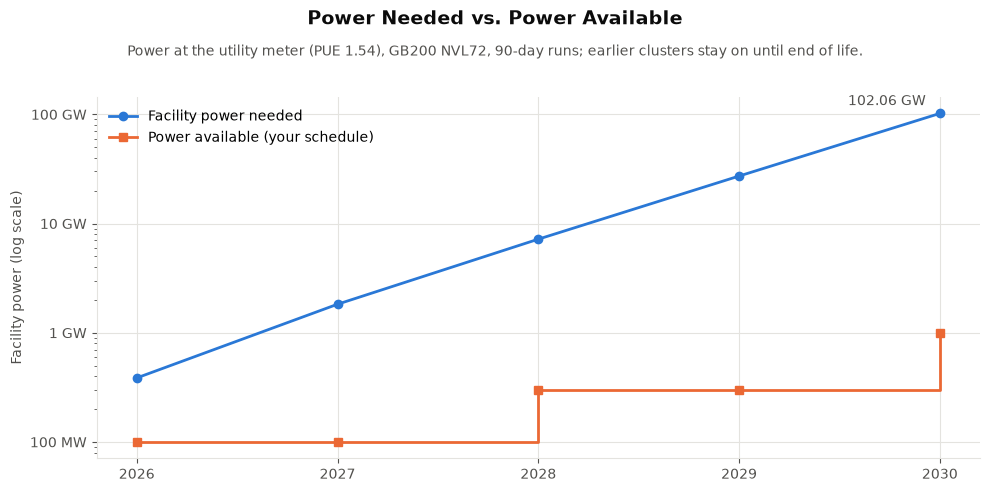

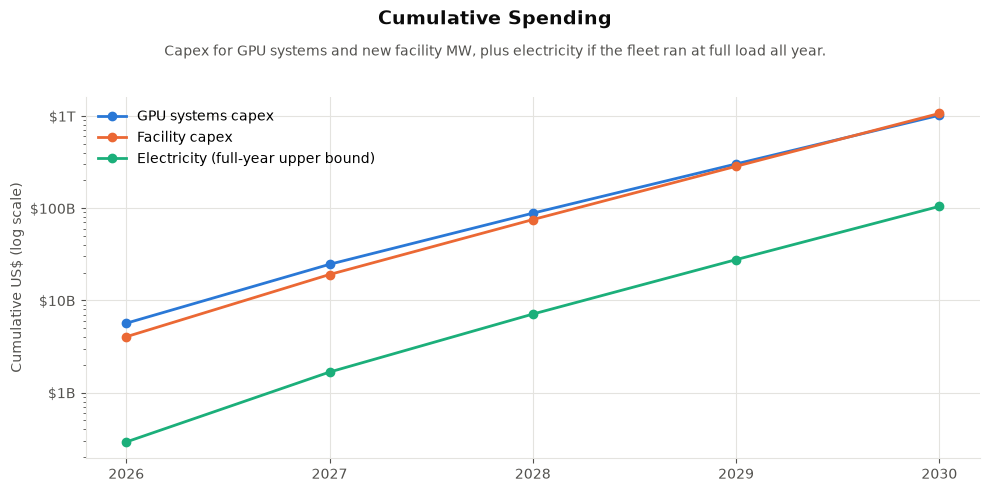

In [5]:
import os

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # categorical slots 1-3 (validated palette)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10,
    "legend.frameon": False,
})
os.makedirs("images", exist_ok=True)


def tick_mw(v, _=None):
    """Axis tick label for power: 100 MW, 1 GW, 10 GW (no trailing zeros)."""
    return f"{v/1000:g} GW" if v >= 1000 else f"{v:g} MW"


def tick_money(v, _=None):
    """Axis tick label for money: $1B, $10B, $1T (no trailing zeros)."""
    for unit, div in (("T", 1e12), ("B", 1e9), ("M", 1e6), ("K", 1e3)):
        if v >= div:
            return f"${v/div:g}{unit}"
    return f"${v:g}"


def add_header(fig, title, subtitle):
    """Centered bold title with a gray subtitle, above the plot area."""
    plt.tight_layout()
    fig.subplots_adjust(top=0.80)
    fig.text(0.5, 0.975, title, ha="center", va="top", fontsize=14, fontweight="bold", color=INK)
    fig.text(0.5, 0.905, subtitle, ha="center", va="top", fontsize=10, color=INK2)


# ---- Chart 1: power needed vs. power available ----
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(plan.index, plan.facility_mw_needed, marker="o", markersize=6, color=SERIES[0],
        label="Facility power needed")
ax.plot(plan.index, plan.facility_mw_available, drawstyle="steps-post", marker="s", markersize=6,
        color=SERIES[1], label="Power available (your schedule)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(tick_mw))
ax.set_ylabel("Facility power (log scale)")
ax.set_xticks(plan.index)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
last = plan.index[-1]
ax.annotate(fmt_mw(plan.facility_mw_needed[last]), (last, plan.facility_mw_needed[last]),
            textcoords="offset points", xytext=(-10, 6), ha="right", color=INK2)
fleet_note = "earlier clusters stay on until end of life" if KEEP_OLD_CLUSTERS_RUNNING else "only that year's cluster"
add_header(fig, "Power Needed vs. Power Available",
           f"Power at the utility meter (PUE {PUE}), {HARDWARE_NAME}, {TRAINING_DAYS}-day runs; {fleet_note}.")
fig.savefig("images/power_needed_vs_available.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

# ---- Chart 2: cumulative spending ----
cum = pd.DataFrame({
    "GPU systems capex": plan.hardware_capex.cumsum(),
    "Facility capex": plan.facility_capex.cumsum(),
    "Electricity (full-year upper bound)": plan.electricity_full_year.cumsum(),
})
fig, ax = plt.subplots(figsize=(10, 5))
for color, col in zip(SERIES, cum.columns):
    ax.plot(cum.index, cum[col], marker="o", markersize=6, color=color, label=col)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(tick_money))
ax.set_ylabel("Cumulative US$ (log scale)")
ax.set_xticks(cum.index)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
add_header(fig, "Cumulative Spending",
           "Capex for GPU systems and new facility MW, plus electricity if the fleet ran at full load all year.")
fig.savefig("images/cumulative_spending.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 6. One run in detail, and what moves the answer

The first table is the `START_YEAR` run. The sensitivity tables show how facility power and facility capex move with the inputs that have the most spread.

In [6]:
y0 = START_YEAR
r0 = runs[y0]
c_min_pf_days = (r0["train_flop"] / 2) / PF_DAY_FLOP
n_k, d_k = model_shape(r0["train_flop"], "kaplan")
n_c, d_c = model_shape(r0["train_flop"], "chinchilla")

detail = pd.Series({
    "Training compute": f"{r0['train_flop']:.2e} FLOP  ({r0['train_flop']/PF_DAY_FLOP:,.0f} PF-days)",
    "Model shape - Chinchilla": f"{fmt_count(n_c)} params x {fmt_count(d_c)} tokens",
    "Model shape - Kaplan Table 6": f"{fmt_count(n_k)} params x {fmt_count(d_k)} tokens",
    "Peak compute needed": f"{r0['peak_flops']/1e18:,.0f} EFLOP/s",
    f"{HARDWARE_NAME} GPUs (racks)": f"{r0['gpu_equiv_today']:,.0f}  ({r0['gpu_equiv_today']/HARDWARE[HARDWARE_NAME]['gpus_per_system']:,.0f} racks)",
    "IT power": fmt_mw(r0["it_mw"]),
    "Facility power": fmt_mw(r0["facility_mw"]),
    "Energy for the run": f"{r0['energy_mwh']/1e3:,.0f} GWh",
    "Electricity cost for the run": fmt_money(r0["energy_cost"]),
    "GPU systems capex": fmt_money(r0["hardware_capex"]),
    "Facility capex for this IT load (C&W low / mid / high)":
        " / ".join(fmt_money(r0["it_mw"] * v) for v in
                   (FACILITY_CAPEX_RANGE_USD_PER_MW[0], FACILITY_CAPEX_USD_PER_MW, FACILITY_CAPEX_RANGE_USD_PER_MW[1])),
}, name=f"{y0} run")
display(detail.to_frame())

print(f"Kaplan's C* (where the fitted trends must break down) ~ {KAPLAN['C_star_pf_days']:.0e} PF-days.")
print(f"This run's C_min ~ {c_min_pf_days:.1e} PF-days = {c_min_pf_days/KAPLAN['C_star_pf_days']:,.0f}x past C*.")
print("So Kaplan's loss curve is not used to predict model quality here.")

# Sensitivity: facility MW for the START_YEAR run
mfus, days = [0.30, 0.40, 0.50], [60, 90, 120]
sens = pd.DataFrame(
    [[fmt_mw(size_run(r0["train_flop"], y0, training_days=d, mfu=m)["facility_mw"]) for d in days] for m in mfus],
    index=[f"MFU {m:.0%}" for m in mfus], columns=[f"{d}-day run" for d in days])
print(f"\nFacility power for the {y0} run, by MFU and run length (PUE {PUE}):")
display(sens)

pues = [1.1, 1.3, 1.54]
sens_pue = pd.Series({f"PUE {p}": fmt_mw(size_run(r0["train_flop"], y0, pue=p)["facility_mw"]) for p in pues},
                     name="Facility power")
print("By PUE (1.54 = 2025 survey average; lower values = new purpose-built AI halls):")
display(sens_pue.to_frame())

,2026 run
Training compute,"9.50e+26 FLOP (10,995,370 PF-days)"
Model shape - Chinchilla,2.8T params x 56.3T tokens
Model shape - Kaplan Table 6,108.2T params x 1.5T tokens
Peak compute needed,339 EFLOP/s
GB200 NVL72 GPUs (racks),"135,745 (1,885 racks)"
IT power,250.6 MW
Facility power,385.9 MW
Energy for the run,834 GWh
Electricity cost for the run,$71.86M
GPU systems capex,$5.66B


Kaplan's C* (where the fitted trends must break down) ~ 1e+04 PF-days.
This run's C_min ~ 5.5e+06 PF-days = 550x past C*.
So Kaplan's loss curve is not used to predict model quality here.

Facility power for the 2026 run, by MFU and run length (PUE 1.54):


,60-day run,90-day run,120-day run
MFU 30%,771.9 MW,514.6 MW,385.9 MW
MFU 40%,578.9 MW,385.9 MW,289.5 MW
MFU 50%,463.1 MW,308.7 MW,231.6 MW


By PUE (1.54 = 2025 survey average; lower values = new purpose-built AI halls):


,Facility power
PUE 1.1,275.7 MW
PUE 1.3,325.8 MW
PUE 1.54,385.9 MW


### Reality check against an outside projection

Epoch AI's *Trends in AI Supercomputers* (arXiv:2504.16026) projects that the **leading** AI supercomputer in 2030 will deliver about $2\times10^{22}$ 16-bit FLOP/s and need about **9 GW**. The cell below compares that with the single cluster this notebook sizes for `END_YEAR`. A big gap usually means one of the inputs is putting all the growth in one place. For example, a fixed `TRAINING_DAYS` assumes all compute growth comes from bigger clusters, while Epoch notes that growth has also come from **training for longer** and from faster chips.

In [7]:
EPOCH_2030_FLOPS, EPOCH_2030_GW = 2e22, 9.0     # arXiv:2504.16026, executive summary (June 2030 projection)
if END_YEAR >= 2030:
    r30 = runs[2030]
    print(f"This notebook, 2030 single run : {r30['peak_flops']:.2e} FLOP/s peak, {fmt_mw(r30['facility_mw'])} facility power")
    print(f"Epoch projection, 2030 leader  : {EPOCH_2030_FLOPS:.2e} FLOP/s, {EPOCH_2030_GW:.0f} GW")
    print(f"Ratio (notebook / Epoch)       : {r30['peak_flops']/EPOCH_2030_FLOPS:.1f}x compute, "
          f"{r30['facility_mw']/1e3/EPOCH_2030_GW:.1f}x power")
    days_to_match = TRAINING_DAYS * r30["peak_flops"] / EPOCH_2030_FLOPS
    print(f"To fit the 2030 run on Epoch's projected machine at these MFU/goodput values, it would run ~{days_to_match:,.0f} days.")

This notebook, 2030 single run : 2.12e+23 FLOP/s peak, 74.81 GW facility power
Epoch projection, 2030 leader  : 2.00e+22 FLOP/s, 9 GW
Ratio (notebook / Epoch)       : 10.6x compute, 8.3x power
To fit the 2030 run on Epoch's projected machine at these MFU/goodput values, it would run ~954 days.


## 7. Checks against published numbers

These cells re-derive figures that the sources report directly. If an edit breaks the core math, an `assert` fails here.

In [8]:
checks = []

# 1. Kaplan Sec. 2.1: 1 PF-day = 8.64e19 FLOP
checks.append(("PF-day = 8.64e19 FLOP (Kaplan Sec. 2.1)", PF_DAY_FLOP, 8.64e19))

# 2. Llama 3: 405B params x 15.6T tokens with C = 6ND vs. reported 3.8e25 FLOP
checks.append(("Llama 3 405B: 6ND vs reported 3.8e25 FLOP", 6 * 405e9 * 15.6e12, 3.8e25))

# 3. Chinchilla Table A3: 1B params <-> 1.21e20 FLOP, 20.2B tokens
n, d = model_shape(1.21e20, "chinchilla")
checks.append(("Chinchilla A3: params for 1.21e20 FLOP", n, 1.0e9))
checks.append(("Chinchilla A3: tokens for 1.21e20 FLOP", d, 20.2e9))

# 4. GB200 NVL72 per-GPU dense BF16 = 180 PF / 72 = 2.5 PF (SemiAnalysis also lists 2,500 TFLOP/s)
checks.append(("GB200 BF16 dense per GPU", HARDWARE["GB200 NVL72"]["peak_flops_per_gpu"], 2.5e15))

# 5. Kaplan Table 6 internal consistency: D from C/(6N) vs D_e * C_min^0.27 (constants are rounded in the paper)
c_min = 1e3
n_t6 = KAPLAN["N_e"] * c_min ** KAPLAN["p_N"]
d_from_6nd = (2 * c_min * PF_DAY_FLOP) / (6 * n_t6)
d_t6 = KAPLAN["D_e"] * c_min ** KAPLAN["p_D"]
checks.append(("Kaplan Table 6: D via 6ND vs D_e*C_min^0.27", d_from_6nd, d_t6))

tol = {0: 1e-9, 1: 0.01, 2: 0.01, 3: 0.01, 4: 1e-9, 5: 0.15}
out = []
for i, (label, got, ref) in enumerate(checks):
    err = abs(got - ref) / ref
    assert err <= tol[i], f"{label}: off by {err:.1%}"
    out.append(dict(check=label, computed=f"{got:.4g}", reported=f"{ref:.4g}", diff=f"{err:.2%}", tolerance=f"{tol[i]:.0%}"))
display(pd.DataFrame(out).set_index("check"))

# 6. Round-trip on Llama 3 run time on reported hardware (Table 4: 16,384 H100s at 400 TFLOP/s per GPU, BF16)
days_pure = 3.8e25 / (16384 * 400e12) / 86400
print(f"Llama 3 405B at the reported 400 TFLOP/s/GPU on 16,384 H100s: {days_pure:.0f} days of pure compute "
      f"({days_pure/GOODPUT:.0f} days at {GOODPUT:.0%} goodput).")
h100_run = size_run(3.8e25, START_YEAR, training_days=days_pure / GOODPUT, mfu=400e12/989e12,
                    hardware="H100 (DGX H100)")
print(f"Round trip: fed those same inputs, the calculator sizes it at {h100_run['gpu_equiv_today']:,.0f} H100s "
      f"(reported: 16,384) and {fmt_mw(h100_run['it_mw']/CLUSTER_OVERHEAD)} of GPU-system power at DGX max rating.")

,computed,reported,diff,tolerance
check,,,,
PF-day = 8.64e19 FLOP (Kaplan Sec. 2.1),8.64e+19,8.64e+19,0.00%,0%
Llama 3 405B: 6ND vs reported 3.8e25 FLOP,3.791e+25,3.8e+25,0.24%,1%
Chinchilla A3: params for 1.21e20 FLOP,1.004e+09,1e+09,0.42%,1%
Chinchilla A3: tokens for 1.21e20 FLOP,2.008e+10,2.02e+10,0.58%,1%
GB200 BF16 dense per GPU,2.5e+15,2.5e+15,0.00%,0%
Kaplan Table 6: D via 6ND vs D_e*C_min^0.27,1.43e+11,1.291e+11,10.77%,15%


Llama 3 405B at the reported 400 TFLOP/s/GPU on 16,384 H100s: 67 days of pure compute (75 days at 90% goodput).
Round trip: fed those same inputs, the calculator sizes it at 16,384 H100s (reported: 16,384) and 20.9 MW of GPU-system power at DGX max rating.


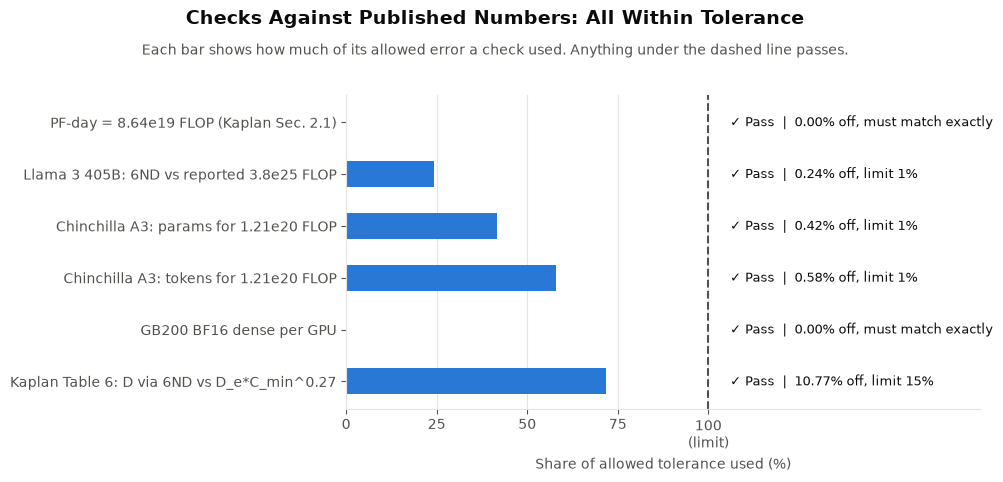

In [9]:
# Visual summary of the checks above: how much of each check's allowed tolerance was used.
# Also saved to images/validation_checks.png so the README (or a website) can show it.
import os

labels = [c[0] for c in checks]
errs = [abs(got - ref) / ref for _, got, ref in checks]
used = [errs[i] / tol[i] for i in range(len(checks))]
all_pass = all(u <= 1 for u in used)

fig, ax = plt.subplots(figsize=(10, 0.55 * len(labels) + 1.6))
ypos = list(range(len(labels)))[::-1]
ax.barh(ypos, [u * 100 for u in used], height=0.5, color=SERIES[0])
ax.axvline(100, color=INK2, linewidth=1.5, linestyle="--")
for yi, u, e, t in zip(ypos, used, errs, [tol[i] for i in range(len(checks))]):
    limit_txt = "must match exactly" if t < 1e-6 else f"limit {t:.0%}"
    verdict = "\u2713 Pass" if u <= 1 else "\u2717 FAIL"
    ax.text(106, yi, f"{verdict}  |  {e:.2%} off, {limit_txt}", va="center", color=INK, fontsize=9)
ax.set_yticks(ypos)
ax.set_yticklabels(labels)
ax.set_xlim(0, 175)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0", "25", "50", "75", "100\n(limit)"])
ax.set_xlabel("Share of allowed tolerance used (%)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
plt.tight_layout()
fig.subplots_adjust(top=0.80)
fig.text(0.5, 0.975, "Checks Against Published Numbers: " + ("All Within Tolerance" if all_pass else "FAILURES FOUND"),
         ha="center", va="top", fontsize=14, fontweight="bold", color=INK)
fig.text(0.5, 0.905, "Each bar shows how much of its allowed error a check used. Anything under the dashed line passes.",
         ha="center", va="top", fontsize=10, color=INK2)
os.makedirs("images", exist_ok=True)
fig.savefig("images/validation_checks.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 8. Limits — read before using the numbers

- **Run size is the biggest lever and the least certain.** The default extrapolates Epoch's 5×/year frontier trend from a 2024 anchor. That isn't a forecast for your organization. Use `TARGET_FLOP_OVERRIDE` with your own plan.
- **Power numbers use maximum system ratings** (DGX H100 10.2 kW max; GB200 NVL72 ~120 kW). Average draw during training is usually lower, so energy cost leans high. The capacity you must *provision* is closer to the rating.
- **Hardware improvement is a smooth trend.** Real gains arrive in steps when a new generation ships. To model a specific product, add it to `HARDWARE`.
- **Costs left out:** scale-out networking, storage, land, staff, financing, taxes, and any power-delivery charges from the utility. Facility $/MW is a midpoint of the Cushman & Wakefield range. It's applied per MW of IT load, the usual way that metric is quoted, but check the guide's own definition for your market.
- **Interconnection lead time varies a lot by utility** (reported ranges run from about 1 year to over a decade). Use the figure your utility gives you.
- **Scaling laws here set model shape only.** Kaplan's constants depend on that paper's tokenizer and data, and both papers' fits were made on runs far smaller than today's.

## Sources

**Scaling laws**
- Kaplan et al. (2020), *Scaling Laws for Neural Language Models* — https://arxiv.org/abs/2001.08361
- Hoffmann et al. (2022), *Training Compute-Optimal Large Language Models* — https://arxiv.org/abs/2203.15556
- Llama Team, Meta (2024), *The Llama 3 Herd of Models* (3.8e25 FLOP, 15.6T tokens, 38–43% MFU, >90% effective training time) — https://arxiv.org/abs/2407.21783

**Hardware**
- NVIDIA H100 product page (700 W TDP; BF16 1,979 TFLOPS with sparsity) — https://www.nvidia.com/en-us/data-center/h100/
- NVIDIA DGX H100/H200 user guide (10.2 kW max) — https://docs.nvidia.com/dgx/dgxh100-user-guide/introduction-to-dgxh100.html
- NVIDIA GB200 NVL72 page (360 PFLOPS FP16/BF16 sparse; dense is half) — https://www.nvidia.com/en-us/data-center/gb200-nvl72/
- SemiAnalysis InferenceX, GB200 NVL72 (2,500 TFLOP/s BF16 dense per GPU) — https://inferencex.semianalysis.com/chips/gb200-nvl72
- NVIDIA DGX GB200 user guide (rack ≈120 kW) — https://docs.nvidia.com/dgx/dgxgb200-user-guide/hardware.html
- Tom's Hardware, GB200 NVL72 price estimates ($2.8M–$3.4M) — https://www.tomshardware.com/tech-industry/artificial-intelligence/price-of-nvidias-vera-rubin-nvl72-racks-skyrockets-to-as-much-as-usd8-8-million-apiece-but-server-makers-margins-will-be-tight-nvidia-is-moving-closer-to-shipping-entire-full-scale-systems
- Vertiv 360AI Reference Design 020 (GB200 NVL72; 6,912 kW IT) — https://www.vertiv.com/493cf5/globalassets/campaigns/ai-hub/vertiv-reference-design-020-ds-en-na-2024-gr-00109-web.pdf

**Trends**
- Epoch AI, Trends in AI (5×/yr frontier LM training compute; +49%/yr chip performance per dollar; GW-scale build ≈2 yrs) — https://epoch.ai/trends
- Epoch AI, *Trends in AI Supercomputers* (perf per watt +1.34×/yr) — https://arxiv.org/abs/2504.16026

**Facility, power, prices**
- Uptime Institute Global Data Center Survey 2025 (average PUE 1.54) — https://intelligence.uptimeinstitute.com/resource/uptime-institute-global-data-center-survey-2025
- U.S. EIA, electricity prices (2025 industrial 8.62¢/kWh) — https://www.eia.gov/energyexplained/electricity/prices-and-factors-affecting-prices.php
- Cushman & Wakefield 2026 Data Center Development Cost Guide ($8.9M–$23.3M per MW, U.S./Canada) — https://finviz.com/news/388803/cushman-wakefield-releases-2026-data-center-development-cost-guide-citing-21-rise-in-per-mw-construction-costs and https://www.credaily.com/?p=222025
- EC&M, *How Long Does It Take to Power a Data Center?* (JLL: ~4-yr average wait; 18–24-month shell) — https://www.ecmag.com/magazine/articles/article-detail/how-long-does-it-take-to-power-a-data-center
- Utility Dive (1–5 yrs regulated vs 8+ in parts of PJM) — https://www.utilitydive.com/news/efforts-to-curb-data-center-speculation-gain-ground-across-the-us/830495/
- Bloomberg (Dominion: up to 7 yrs for >100 MW) — https://www.bloomberg.com/news/articles/2024-08-29/data-centers-face-seven-year-wait-for-power-hookups-in-virginia
- DataGravity, *How much does an NVIDIA NVL72 cost?* (4–6-yr depreciation practice) — https://www.datagravity.dev/p/how-much-does-an-nvidia-nvl72-cost
- Lawrence Berkeley National Lab, *Queued Up* (generator queues; background only — not large-load wait times) — https://emp.lbl.gov/queues